# Example of the `aitlas` toolbox in the context of multi label image classification

This notebook shows a sample implementation of a multi label image classification using the `aitlas` toolbox using the Big Earth Net multi label dataset with 19 labels.

In [ ]:
from aitlas.datasets import BigEarthNetDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "lmdb_path": "./data/BigEarthNet/lmdb",
    "import_to_lmdb": "false",
    "csv_file": "./data/BigEarthNet/train.csv",
    "data_dir": "./data/BigEarthNet/BigEarthNet-v1.0",
    "selection": "rgb",
    "version": "19 labels",
}
dataset = BigEarthNetDataset(dataset_config)

## Show images from the dataset

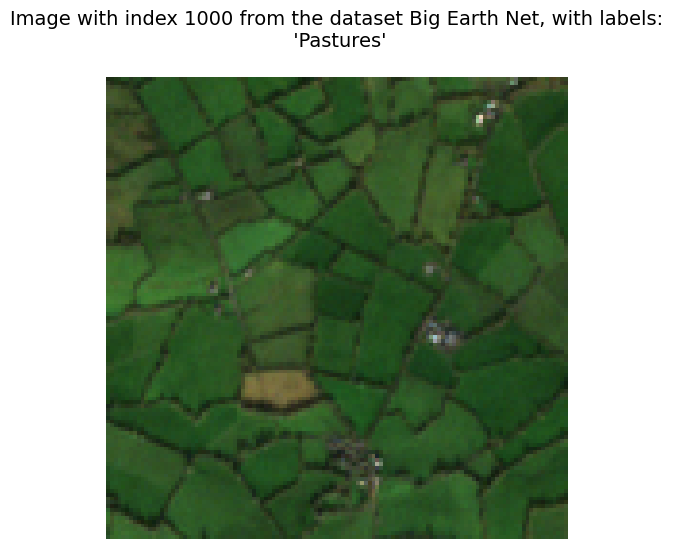

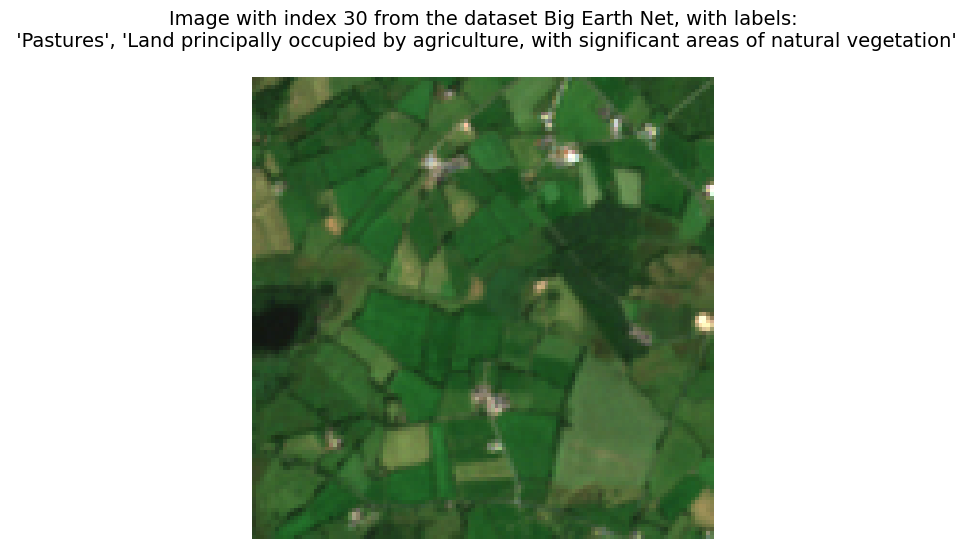

In [8]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)

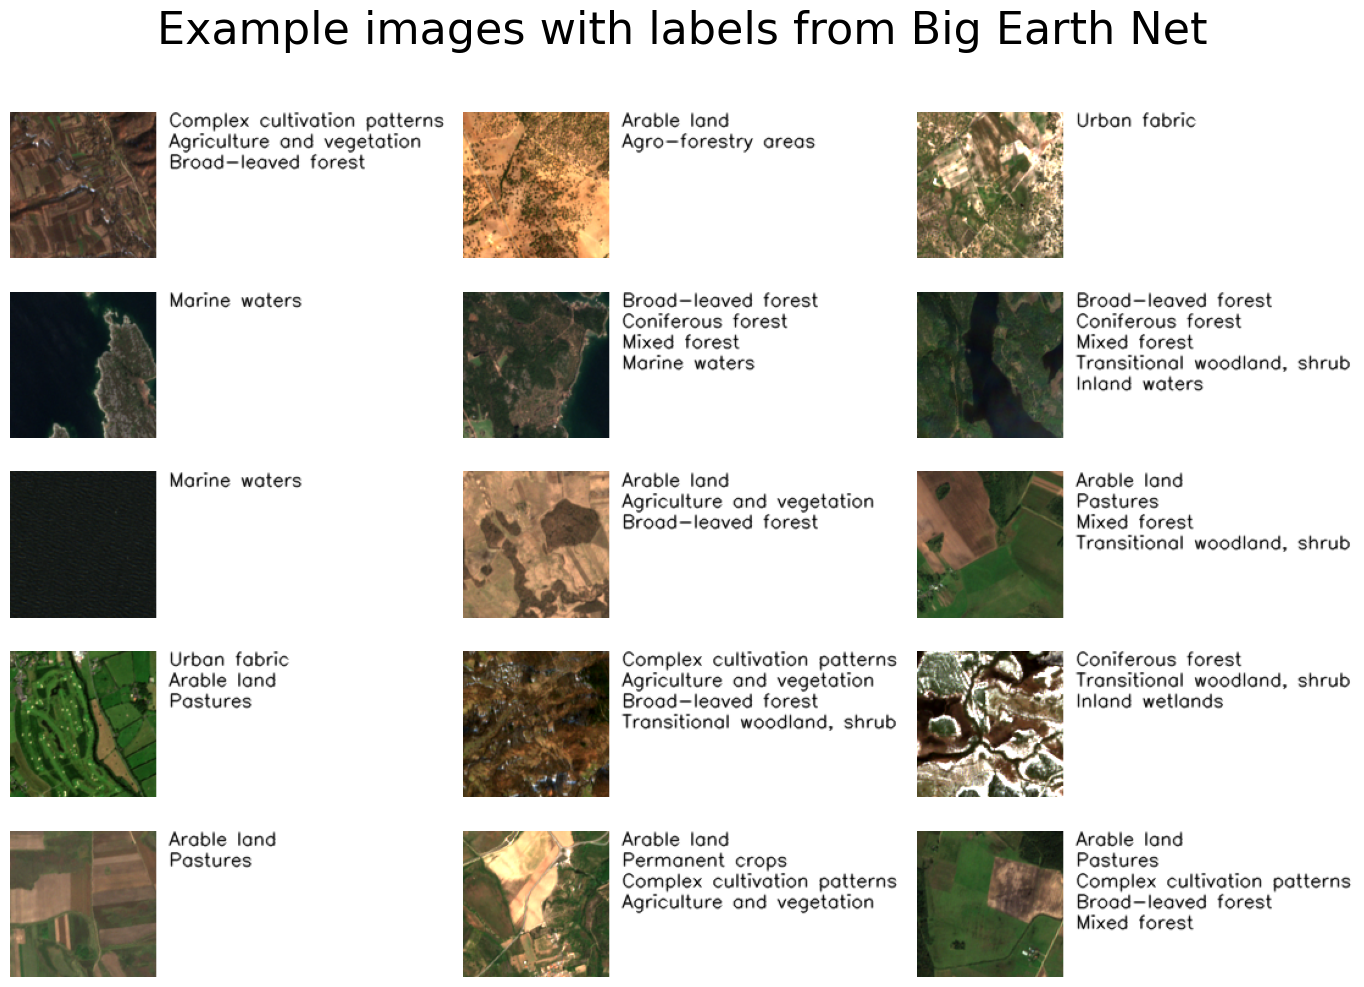

In [9]:
fig3 = dataset.show_batch(15)

## Inspect the data

In [14]:
dataset.labels_stats()

Processed 100000 of 269695
Processed 200000 of 269695


'Minimum number of labels: 1.0, Maximum number of labels: 11.0, Average number of labels: 2.898485326016426'

In [11]:
dataset.data_distribution_table()

Processed 100000 of 269695
Processed 200000 of 269695


,Label,Count
0,Urban fabric,38783
1,Industrial or commercial units,6182
2,Arable land,100394
3,Permanent crops,15862
4,Pastures,50981
5,Complex cultivation patterns,53534
6,"Land principally occupied by agriculture, with...",67260
7,Agro-forestry areas,15790
8,Broad-leaved forest,73411
9,Coniferous forest,86569


Processed 100000 of 269695
Processed 200000 of 269695


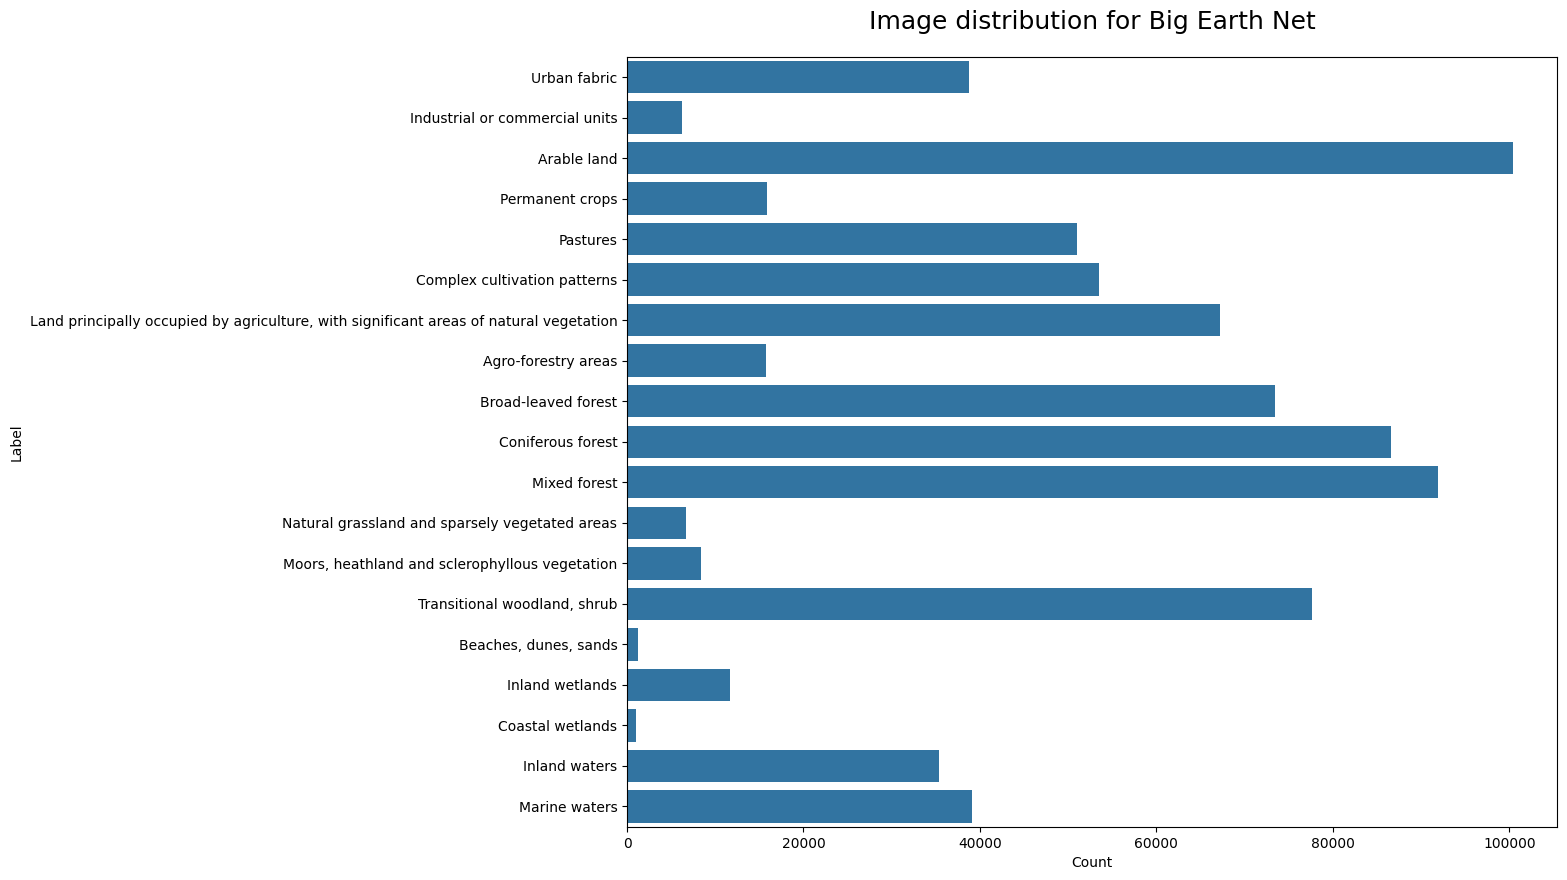

In [13]:
dataset.data_distribution_barchart();

## Load train and test splits

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "lmdb_path": "./data/BigEarthNet/lmdb",
    "import_to_lmdb": "false",
    "csv_file": "./data/BigEarthNet/train.csv",
    "data_dir": "./data/BigEarthNet/BigEarthNet-v1.0",
    "transforms": ["aitlas.transforms.big_earth_net.ResizeToTensorNormalizeRGB"],
    "bands10_mean": [429.9430203, 614.21682446, 590.23569706],
    "bands10_std": [572.41639287, 582.87945694, 675.88746967],
    "selection": "rgb",
    "version": "19 labels",
}

train_dataset = BigEarthNetDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "lmdb_path": "./data/BigEarthNet/lmdb",
    "import_to_lmdb": "false",
    "csv_file": "./data/BigEarthNet/val.csv",
    "data_dir": "./data/BigEarthNet/BigEarthNet-v1.0",
    "transforms": ["aitlas.transforms.big_earth_net.ResizeToTensorNormalizeRGB"],
    "bands10_mean": [429.9430203, 614.21682446, 590.23569706],
    "bands10_std": [572.41639287, 582.87945694, 675.88746967],
    "selection": "rgb",
    "version": "19 labels",
}

test_dataset = BigEarthNetDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(269695, 123723)

## Setup and create the model for training

In [ ]:
epochs = 5
model_directory = "./data/BigEarthNet/experiments"
model_config = {
    "num_classes": 19,
    "learning_rate": 0.0001,
    "pretrained": False,
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score"],
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [21]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id="1",
)

2026-08-20 11:46:12,657 INFO Starting training.
training: 100%|██████████| 16856/16856 [07:48<00:00, 36.02it/s]
2026-08-20 11:54:00,703 INFO epoch: 1, time: 468, loss:  0.25111
testing on train set: 100%|██████████| 16856/16856 [03:24<00:00, 82.27it/s]
2026-08-20 11:57:26,359 INFO Accuracy:0.9073596782330137, Accuracy per Class:[0.90775506 0.97742635 0.82458703 0.94826378 0.88778064 0.83829511
 0.80273272 0.96268377 0.82947774 0.88444725 0.82512839 0.95134875
 0.96916517 0.77283598 0.99476446 0.96003263 0.99552828 0.92725486
 0.98032592], Precision Micro:0.7834222377320239, Precision Macro:0.694720010871594, Precision Weighted:0.782083486495566, Precision per Class:[0.79659571 0.72380952 0.896875   0.68331093 0.75940396 0.7207564
 0.70310333 0.79966506 0.76799187 0.82013058 0.8036189  0.24168
 0.57279236 0.64873383 0.40912933 0.83241107 0.15226337 0.93025164
 0.93715734], Recall Micro:0.5427813746071098, Recall Macro:0.41988138627427823, Recall Weighted:0.5427813746071098, Recall per C

0.18104376554816226

## Predictions

2026-08-24 07:13:50,004 INFO Loading checkpoint /home/dragik/data/BigEarthNet/experiments/checkpoint.pth.tar
2026-08-24 07:13:50,170 INFO Loaded checkpoint /home/dragik/data/BigEarthNet/experiments/checkpoint.pth.tar at epoch 6


125866


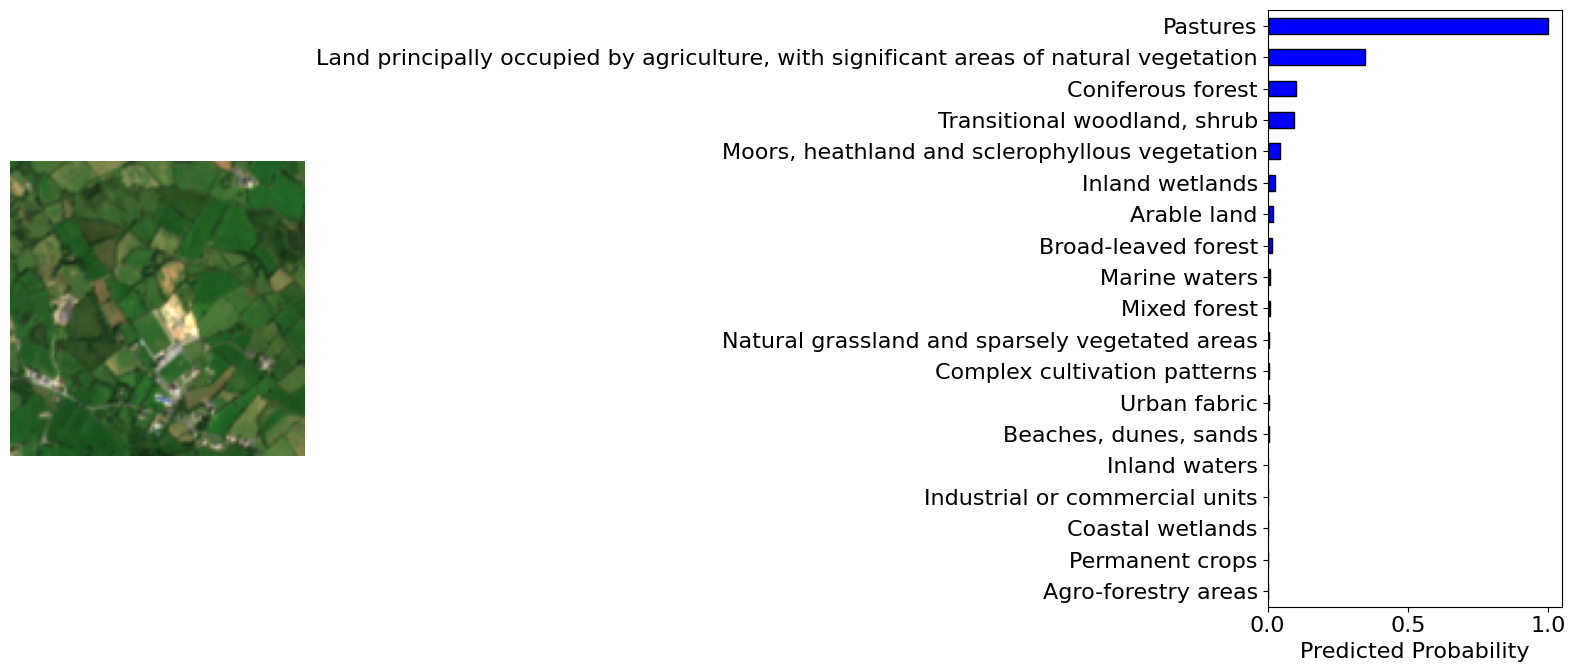

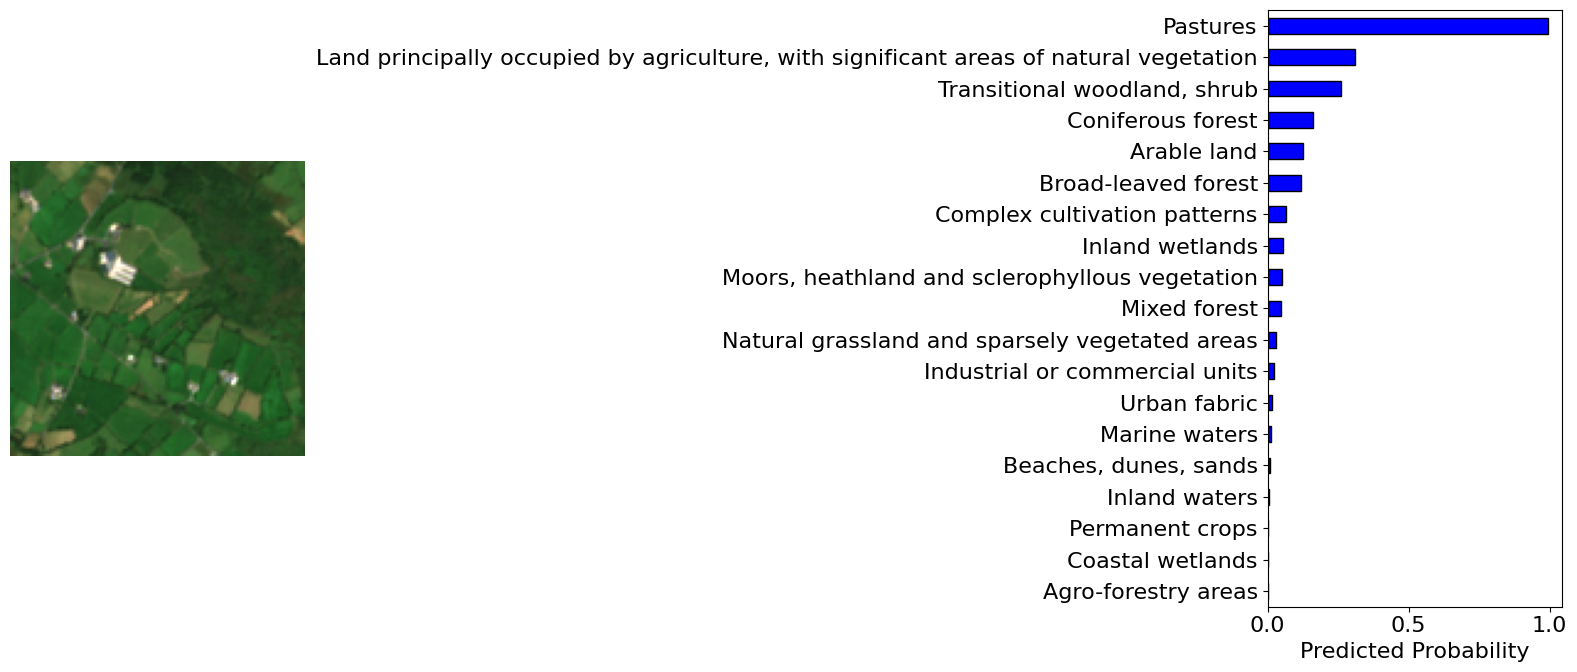

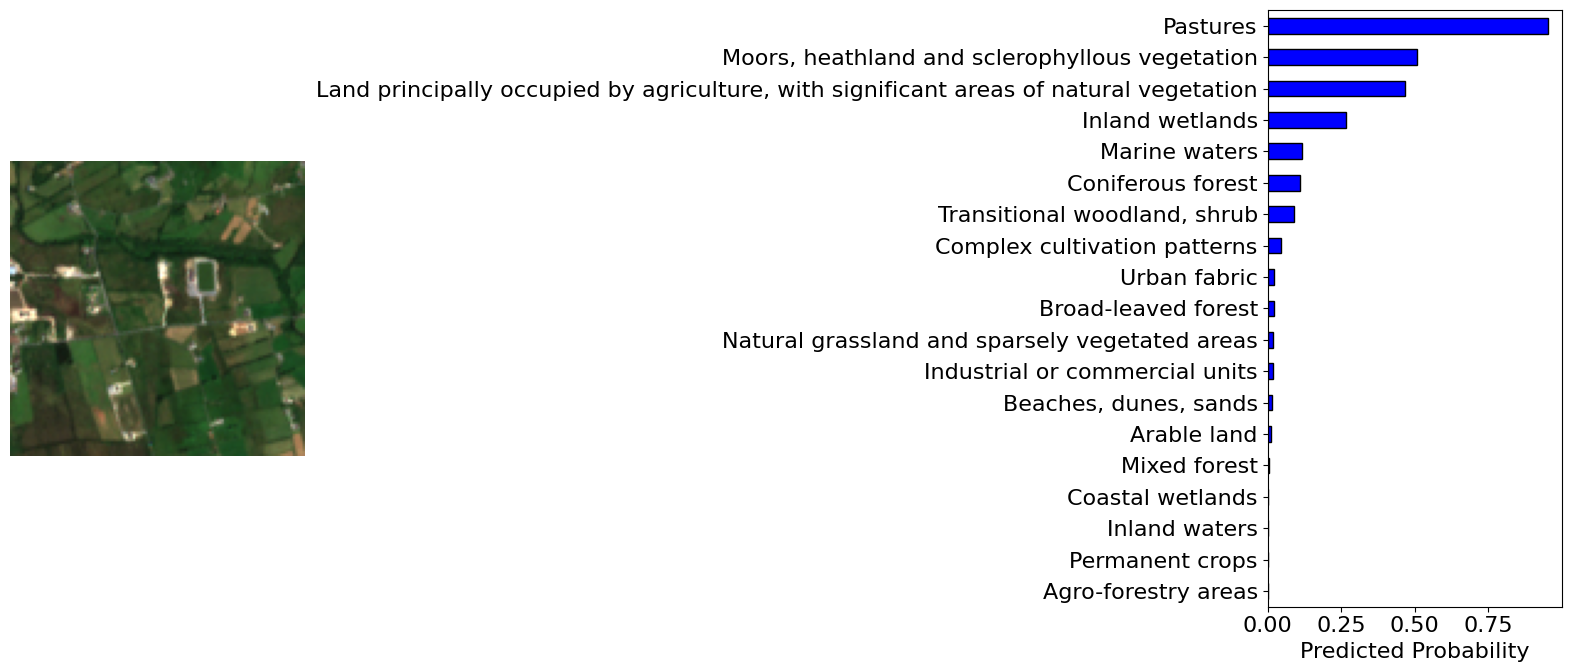

In [ ]:
model_path = "./data/BigEarthNet/experiments/checkpoint.pth.tar"
labels = ["Urban fabric","Industrial or commercial units","Arable land","Permanent crops","Pastures","Complex cultivation patterns",
          "Land principally occupied by agriculture, with significant areas of natural vegetation","Agro-forestry areas","Broad-leaved forest",
          "Coniferous forest","Mixed forest","Natural grassland and sparsely vegetated areas","Moors, heathland and sclerophyllous vegetation",
          "Transitional woodland, shrub","Beaches, dunes, sands","Inland wetlands","Coastal wetlands","Inland waters","Marine waters"]

model.load_model(model_path)
transform = ResizeCenterCropFlipHVToTensor()

test_dataset_config = {
    "lmdb_path": "./data/BigEarthNet/lmdb",
    "import_to_lmdb": "false",
    "csv_file": "./data/BigEarthNet/test.csv",
    "data_dir": "./data/BigEarthNet/BigEarthNet-v1.0",
    "selection": "rgb",
    "version": "19 labels",
}

test_dataset = BigEarthNetDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)